# Policy Rate Monitor

This notebook shows how to use the package from Python: load the staged data through the provider, compute the 12-month change, and plot the rates.

If the staged data does not exist yet, run [fetch_and_transform.ipynb](fetch_and_transform.ipynb) first.

## Setup

In [1]:
from datetime import date
from pathlib import Path

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
from policy_rate_monitor.bulk import BulkFileProvider
from policy_rate_monitor.config import FileConfigSource
from policy_rate_monitor.report import charted_series, valid_rows
from policy_rate_monitor.service import load_staged, summary

The notebook is meant to run from `examples/`, so the repository root, `ROOT`, is its parent folder.  
Change `ROOT` if you run the notebook from elsewhere.

In [4]:
ROOT = Path.cwd().parent

In [5]:
config = FileConfigSource(ROOT / "configs" / "bis_cbpol.json").load()
provider = BulkFileProvider(config, ROOT / config.dataset.data_dir)
provider.source_release()

SourceRelease(location='https://data.bis.org/static/bulk/WS_CBPOL_csv_flat.zip', version_id=None, checksum_sha256='79f614ab22c21d172694cd48e9a9d551c7196f53c525008bc7ea4da8831d6494', retrieved_at=datetime.datetime(2026, 11, 19, 22, 44, 41, 308601, tzinfo=TzInfo(0)))

## Load the series

`load_staged` reads what the report needs through the provider: the observations, the series, the findings and the release.  
The observations keep their Arrow types, so the rates stay exact decimals.

In [6]:
data = load_staged(provider)
data.observations.tail()

,series_key,freq,ref_area,date,value,obs_status,is_valid
709979,D.ZA,D,ZA,2026-11-12,7.250000,A,True
709980,D.ZA,D,ZA,2026-11-13,7.250000,A,True
709981,D.ZA,D,ZA,2026-11-14,7.250000,A,True
709982,D.ZA,D,ZA,2026-11-15,<NA>,M,False
709983,D.ZA,D,ZA,2026-11-16,7.250000,A,True


## The 12-month change

The same calculation as `bis-prates report` and the HTTP API's `/summary`.  
Notice that `EA` is an alias of the BIS code `XM`.

In [7]:
snapshots = summary(config, data, ["US", "EA", "GB", "JP", "CH"])
pd.DataFrame([snapshot.model_dump(exclude={"series"}) for snapshot in snapshots])

,requested_ref_area,ref_area,latest_date,latest_value,target_date,prior_date,prior_value,change_bps,status,flags
0,US,US,2026-11-17,3.875000,2025-11-17,2025-11-17,3.875000,0.000000,ok,()
1,EA,XM,2026-11-17,2.500000,2025-11-17,2025-11-17,2.000000,50.000000,ok,()
2,GB,GB,2026-11-16,4.000000,2025-11-16,2025-11-14,4.000000,0.000000,ok,()
3,JP,JP,2026-11-17,1.250000,2025-11-17,2025-11-17,0.500000,75.000000,ok,()
4,CH,CH,2026-11-17,0.000000,2025-11-17,2025-11-17,0.000000,0.000000,ok,()


## Plot the rates

Draw the same chart as `out/policy_rates.png`, from 2015 on: the same series and the same rows.

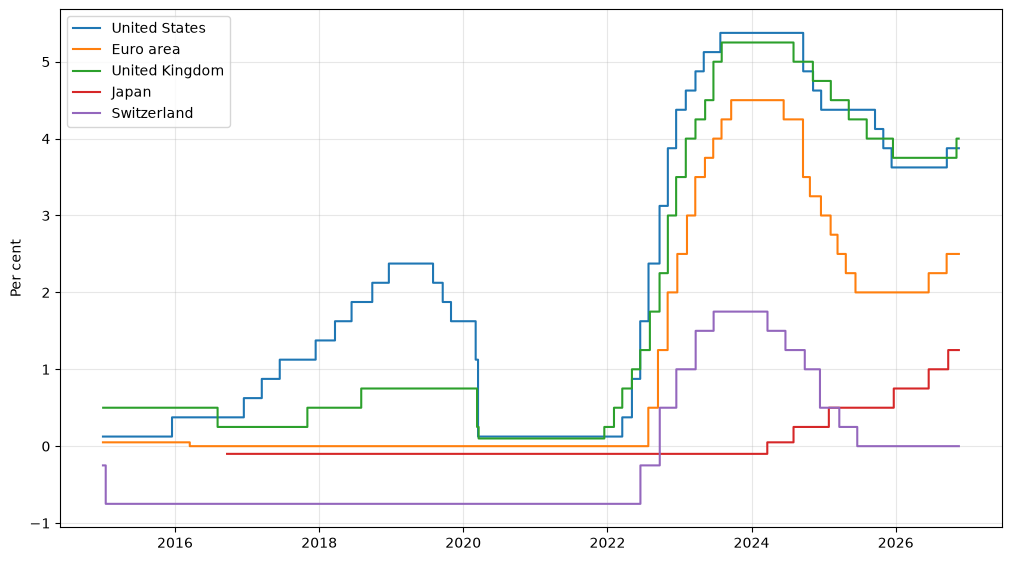

In [8]:
start = date(2015, 1, 1)
figure, axes = plt.subplots(figsize=(10, 5.5), layout="constrained")
for series in charted_series(snapshots):
    rows = valid_rows(data.observations, series.series_key, start)
    axes.step(
        rows["date"],
        rows["value"].astype(float),
        where="post",
        label=series.ref_area_name,
    )
axes.set_ylabel("Per cent")
axes.grid(visible=True, alpha=0.3)
axes.legend();